# 05 · Итоги, ошибки и неопределённость
## Кратко
Предварительно выбранная **D_hierarchy / single** имеет test macro-F1 **0.8656**, распознаёт **32/35** патологических сегментов; к normal отнесено 1, к suspect — 2. Accuracy **92.7%** сравнивается с 78.1% у постоянного normal-baseline, у которого recall патологии равен 0.

Обычный MultiClass на этом test имеет macro-F1 0.8792; уверенного универсального победителя по одному разделению нет. По validation выбран single. Дополнительный порог чувствительности дал test recall 91.4%, precision 68.1%. Ни одна из этих test-проверок не использовалась для повторного выбора модели.

In [2]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.training.ctg_experiments import OUT, MODELS, load_data, FAMILIES, CTG_FEATURES
sns.set_theme(style='whitegrid', palette=['#245b87', '#c47c2d', '#80659e'])
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
data, fingerprint = load_data()

## Контекст и ограничения

In [4]:
test=pd.read_csv(OUT/'test_metrics.csv')
pooled=pd.read_csv(OUT/'nested_pooled_metrics.csv')
validation=pd.read_csv(OUT/'validation_crossfit_metrics.csv')
predictions=pd.read_parquet(OUT/'test_predictions.parquet')
locked=json.loads((OUT/'locked_decision.json').read_text())
print('Чемпион:',locked['family'],'/',locked['architecture'])
print('35 патологических сегментов test; интервалы учитывают группировку по файлам, не всю неопределённость переобучения.')
display(test[['family','architecture','champion','macro_f1','recall_path','precision_path','ap_path','log_loss','brier','path_as_normal']].round(4))

Чемпион: D_hierarchy / single
35 патологических сегментов test; интервалы учитывают группировку по файлам, не всю неопределённость переобучения.


,family,architecture,champion,macro_f1,recall_path,precision_path,ap_path,log_loss,brier,path_as_normal
0,A_multiclass,single,False,0.8792,0.9143,0.8649,0.9271,0.2062,0.1098,0.0286
1,B_sqrt,single,False,0.8657,0.9143,0.8421,0.9207,0.2039,0.1078,0.0286
2,B_balanced,single,False,0.8492,0.9143,0.7442,0.9199,0.2512,0.1391,0.0286
3,C_ovr,single,False,0.8482,0.8286,0.8286,0.9203,0.2269,0.1196,0.1143
4,D_hierarchy,single,True,0.8656,0.9143,0.8205,0.9264,0.2253,0.1206,0.0286
5,D_hierarchy,fold_ensemble,False,0.8490,0.8286,0.8529,0.9258,0.2061,0.1132,0.1143
6,logistic,single,False,0.7915,0.7714,0.7297,0.8416,0.2654,0.1516,0.1429
7,always_normal,constant,False,0.2924,0.0000,0.0000,0.0824,0.6704,0.3644,1.0000


## Матрицы ошибок · финальные процедуры

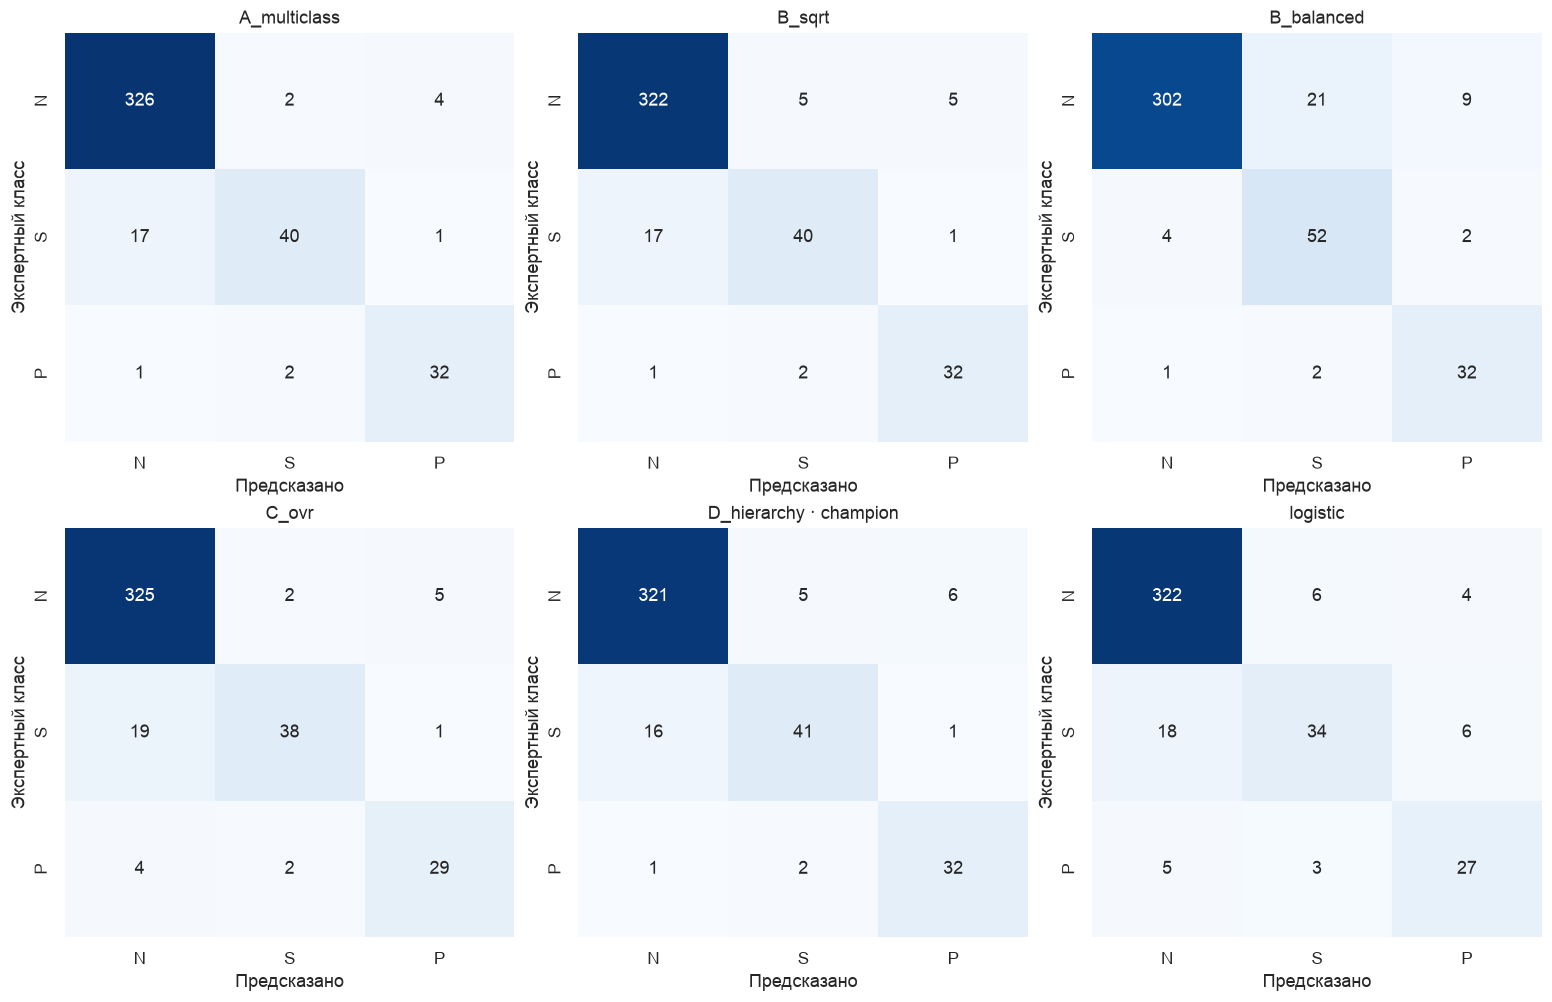

In [6]:
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc
fig,axes=plt.subplots(2,3,figsize=(14,9),constrained_layout=True)
for ax,family in zip(axes.flat,FAMILIES):
    architecture=locked['architecture'] if family==locked['family'] else 'single'
    part=predictions[(predictions.family==family)&(predictions.architecture==architecture)]
    cm=confusion_matrix(part.NSP,part.pred,labels=[1,2,3])
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,vmin=0,vmax=332,ax=ax,xticklabels=['N','S','P'],yticklabels=['N','S','P'])
    ax.set(title=family+(' · champion' if family==locked['family'] else ''),xlabel='Предсказано',ylabel='Экспертный класс')
plt.show()

### Два определения площади под PR-кривой

In [8]:
areas=[]
for (family,architecture),part in predictions.groupby(['family','architecture']):
    precision,recall,_=precision_recall_curve(part.NSP==3,part.p2)
    areas.append({'family':family,'architecture':architecture,'trapezoidal_pr_auc_path':auc(recall,precision)})
areas=pd.DataFrame(areas).merge(test[['family','architecture','ap_path']],on=['family','architecture'])
areas.to_csv(OUT/'test_precision_recall_areas.csv',index=False)
display(areas.round(4))
print('Average Precision и трапецеидальная PR-AUC — разные интегральные оценки; в отборе использовался macro-F1.')

Average Precision и трапецеидальная PR-AUC — разные интегральные оценки; в отборе использовался macro-F1.


,family,architecture,trapezoidal_pr_auc_path,ap_path
0,A_multiclass,single,0.9262,0.9271
1,B_balanced,single,0.9188,0.9199
2,B_sqrt,single,0.9194,0.9207
3,C_ovr,single,0.9195,0.9203
4,D_hierarchy,fold_ensemble,0.9251,0.9258
5,D_hierarchy,single,0.9258,0.9264
6,logistic,single,0.8389,0.8416


## Распознавание pathologic · PR и ROC

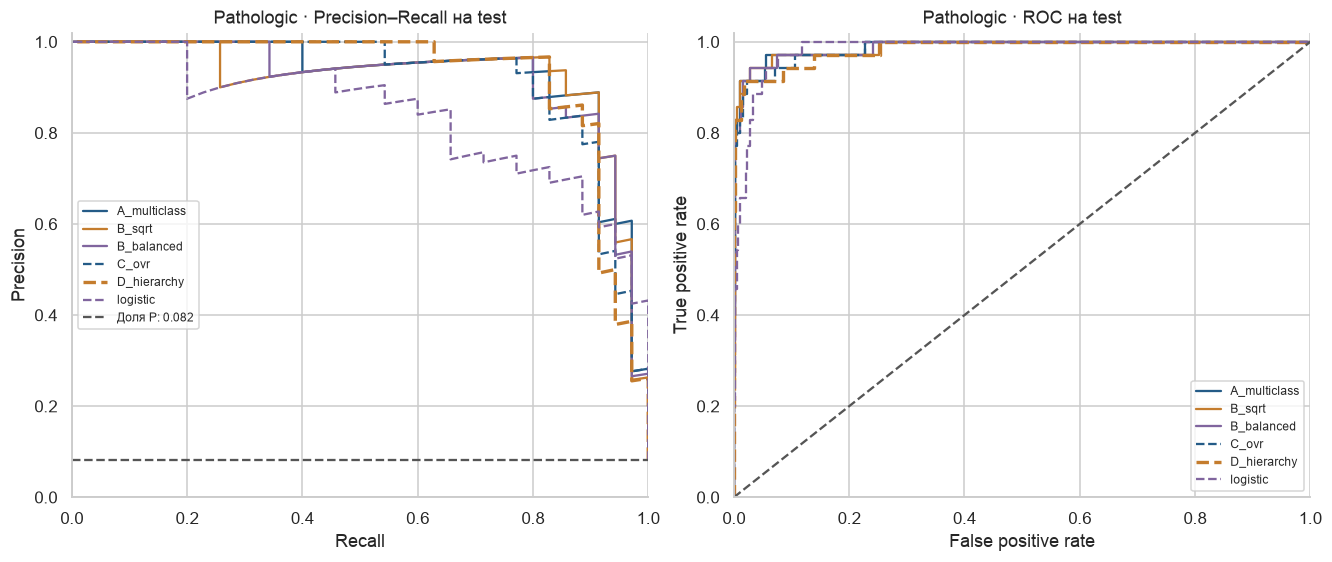

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for index,family in enumerate(FAMILIES):
    architecture=locked['architecture'] if family==locked['family'] else 'single'
    part=predictions[(predictions.family==family)&(predictions.architecture==architecture)]
    precision,recall,_=precision_recall_curve(part.NSP==3,part.p2)
    fpr,tpr,_=roc_curve(part.NSP==3,part.p2)
    style='-' if index<3 else '--'
    width=2.2 if family==locked['family'] else 1.5
    axes[0].plot(recall,precision,label=family,linestyle=style,linewidth=width)
    axes[1].plot(fpr,tpr,label=family,linestyle=style,linewidth=width)
prevalence=(part.NSP==3).mean()
axes[0].axhline(prevalence,color='#555555',linestyle='--',label=f'Доля P: {prevalence:.3f}')
axes[1].plot([0,1],[0,1],color='#555555',linestyle='--')
axes[0].set(title='Pathologic · Precision–Recall на test',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Pathologic · ROC на test',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
plt.show()

## Калибровка патологического класса

В средних probability bins мало сегментов; это описательная кривая, точки не независимы по пациенткам.


,segments,mean_predicted,observed_fraction
probability_bin,,,
"(-0.001, 0.2]",372,0.0045,0.0081
"(0.2, 0.4]",12,0.2860,0.0000
"(0.4, 0.6]",5,0.4963,0.2000
"(0.6, 0.8]",4,0.6567,0.5000
"(0.8, 1.0]",32,0.9559,0.9062


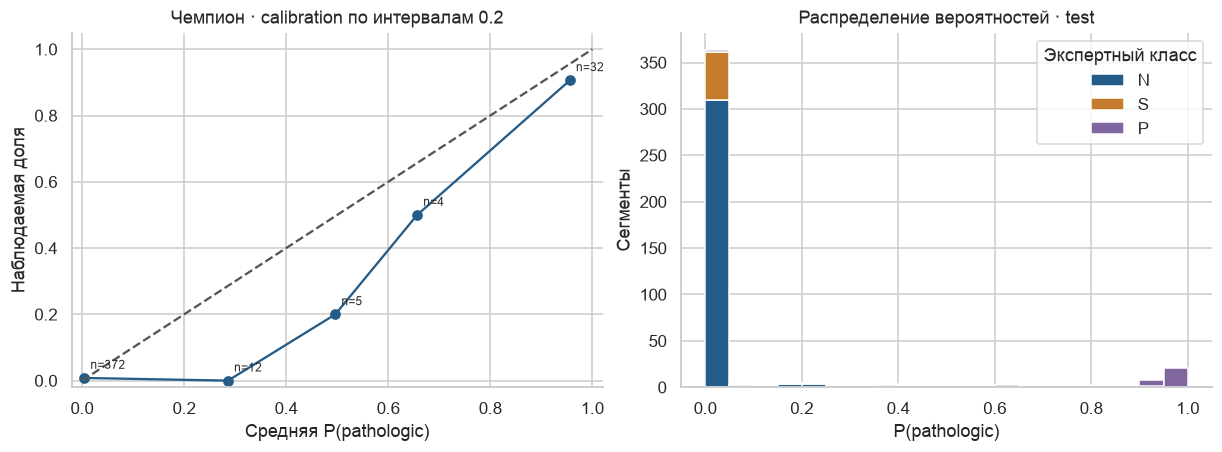

In [12]:
champ=predictions[(predictions.family==locked['family'])&(predictions.architecture==locked['architecture'])].copy()
champ['pathologic']=(champ.NSP==3).astype(int)
champ['probability_bin']=pd.cut(champ.p2,bins=np.linspace(0,1,6),include_lowest=True)
reliability=champ.groupby('probability_bin',observed=False).agg(segments=('NSP','size'),mean_predicted=('p2','mean'),observed_fraction=('pathologic','mean'))
display(reliability.round(4))
nonempty=reliability[reliability.segments>0]
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
axes[0].plot(nonempty.mean_predicted,nonempty.observed_fraction,'o-',color='#245b87')
for row in nonempty.itertuples():
    axes[0].annotate(f'n={row.segments}',(row.mean_predicted,row.observed_fraction),xytext=(4,6),textcoords='offset points',fontsize=8)
axes[0].plot([0,1],[0,1],'--',color='#555555')
axes[0].set(title='Чемпион · calibration по интервалам 0.2',xlabel='Средняя P(pathologic)',ylabel='Наблюдаемая доля',xlim=(-.02,1.02),ylim=(-.02,1.05))
axes[1].hist([champ.loc[champ.NSP==label,'p2'] for label in [1,2,3]],bins=np.linspace(0,1,21),stacked=True,label=['N','S','P'],color=['#245b87','#c47c2d','#80659e'])
axes[1].legend(title='Экспертный класс')
axes[1].set(title='Распределение вероятностей · test',xlabel='P(pathologic)',ylabel='Сегменты')
plt.show()
print('В средних probability bins мало сегментов; это описательная кривая, точки не независимы по пациенткам.')

## Групповые интервалы и тяжёлые ошибки

In [14]:
ci=pd.read_csv(OUT/'champion_test_intervals.csv',index_col=0)
display(ci.loc[['macro_f1','recall_path','precision_path','ap_path','log_loss','brier']].round(4))
errors=champ[champ.NSP!=champ.pred].copy()
errors.to_csv(OUT/'champion_errors.csv',index=False)
display(errors.groupby(['NSP','pred']).agg(segments=('NSP','size'),source_files=('source_file','nunique')))
by_file=champ.assign(error=champ.NSP!=champ.pred).groupby('source_file').agg(segments=('NSP','size'),errors=('error','sum'))
display(by_file.sort_values('errors',ascending=False).head(12))
print('Pathologic → normal:',int(((champ.NSP==3)&(champ.pred==1)).sum()),'из',int((champ.NSP==3).sum()))

Pathologic → normal: 1 из 35


,lower,upper
macro_f1,0.7676,0.9218
recall_path,0.6957,1.0000
precision_path,0.5623,0.9412
ap_path,0.7730,0.9814
log_loss,0.1450,0.3158
brier,0.0762,0.1734


segments  source_files
NSP pred                        
1   2            5             5
    3            6             4
2   1           16             8
    3            1             1
3   1            1             1
    2            2             2

,segments,errors
source_file,,
S0001086.dat,14,5
S8001043.dsp,18,4
S0001072.dat,17,3
Marg_8.txt,6,3
Mrsa_4.txt,3,2
S0001089.dat,12,2
S8001038.dsp,26,2
S0001085.dat,18,2
S0001087_1.dat,4,2


## Дополнительная точка чувствительности
Порог для recall ≥0.90 был выбран на validation и записан до test. Здесь показан перенос этого фиксированного порога. Нужный уровень recall на новых данных не гарантирован, особенно при 10 исходных файлах с pathologic в test.

In [16]:
import joblib
from src.training.ctg_experiments import decisions, metrics
bundle=joblib.load(MODELS/'champion.joblib')
test_frame=data[data.split=='test']
heads=np.mean([member.predict_heads(test_frame[list(CTG_FEATURES)]) for member in bundle.models],axis=0)
calibrated=bundle.calibrator.predict_proba(heads)
policy=locked['policies'][locked['family']+'/'+locked['architecture']]
cutoff=policy['sensitivity_threshold']
sens_pred=decisions(calibrated,cutoff)
operating_point=metrics(test_frame.NSP.to_numpy()-1,calibrated,sens_pred)
display(pd.DataFrame([{'validation_threshold':cutoff,**operating_point}]).round(4))
pd.DataFrame([{'validation_threshold':cutoff,**operating_point}]).to_csv(OUT/'sensitivity_operating_point.csv',index=False)

,validation_threshold,accuracy,macro_f1,balanced_accuracy,recall_path,precision_path,f1_path,recall_normal,recall_suspect,ap_path,roc_auc_path,log_loss,brier,path_as_normal,specificity_path
0,0.22,0.9129,0.8217,0.8282,0.9143,0.6809,0.7805,0.9669,0.6034,0.9256,0.9871,0.2167,0.1186,0.0286,0.9615


## Внутренняя важность признаков
Для CatBoost показана PredictionValuesChange по каждой голове, усреднённая только между фолдами одного и того же типа головы. Это описание обученной модели, не причинный эффект и не оценка улучшения от удаления признака. Для логистики приводятся коэффициенты в преобразованном пространстве.

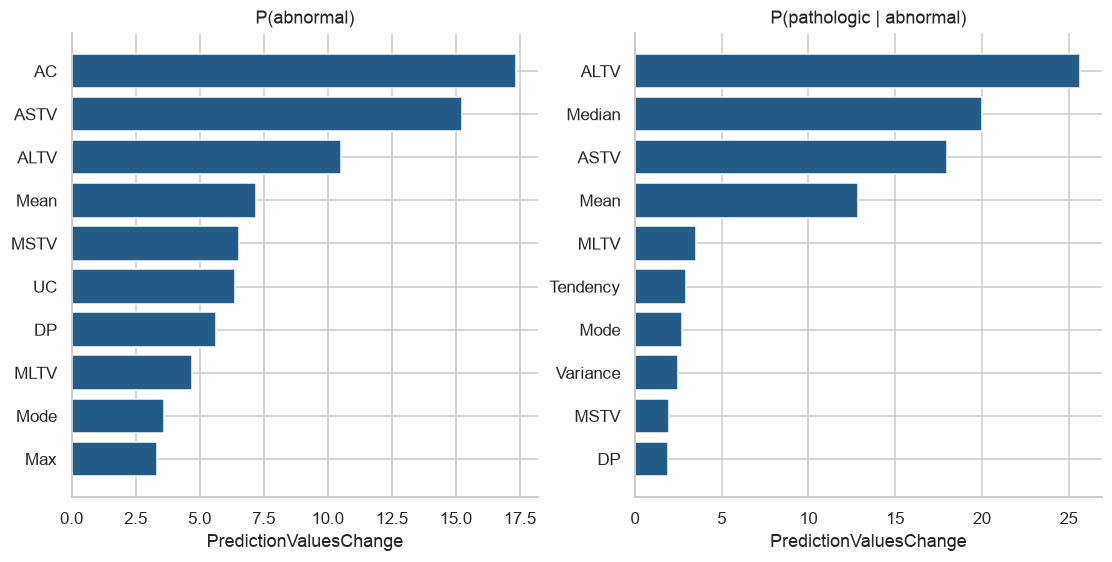

In [18]:
import joblib
bundle=joblib.load(MODELS/'champion.joblib')
importance=[]
if bundle.family!='logistic':
    for fold,member in enumerate(bundle.models):
        for head,model in enumerate(member.models_):
            importance.extend([{'fold':fold,'head':head,'feature':feature,'importance':float(value)}
                               for feature,value in zip(model.feature_names_,model.get_feature_importance())])
    importance=pd.DataFrame(importance)
    importance.to_csv(OUT/'champion_feature_importance.csv',index=False)
    heads=sorted(importance['head'].unique())
    fig,axes=plt.subplots(1,len(heads),figsize=(max(8,5*len(heads)),5),squeeze=False,constrained_layout=True)
    for ax,head in zip(axes.flat,heads):
        ranked=importance[importance['head']==head].groupby('feature').importance.mean().nlargest(10).sort_values()
        ax.barh(ranked.index,ranked.values,color='#245b87')
        title=({'D_hierarchy':['P(abnormal)','P(pathologic | abnormal)'],'C_ovr':['OvR normal','OvR suspect','OvR pathologic']}.get(bundle.family,['MultiClass'])[head])
        ax.set(title=title,xlabel='PredictionValuesChange')
    plt.show()
else:
    model=bundle.models[0].models_[0]
    coef=pd.DataFrame(model.named_steps['model'].coef_.T,index=model.named_steps['features'].get_feature_names_out(),columns=['N','S','P'])
    display(coef.loc[coef.abs().max(axis=1).nlargest(12).index].round(3))

## Нужен ли ансамбль фолдов

In [20]:
comparison=validation[validation.family==locked['family']]
display(comparison[['architecture','mode','macro_f1','recall_path','log_loss','brier']].round(4))
print('По заранее заданному правилу выбран:',locked['architecture'])
print('Проверенные интервалы относятся к фиксированной выбранной модели; результаты одного разделения не доказывают универсальное превосходство.')

По заранее заданному правилу выбран: single
Проверенные интервалы относятся к фиксированной выбранной модели; результаты одного разделения не доказывают универсальное превосходство.


,architecture,mode,macro_f1,recall_path,log_loss,brier
12,single,raw,0.8397,0.8966,0.2385,0.1368
13,single,calibrated,0.8306,0.8621,0.2377,0.1291
14,single,threshold,0.8287,0.8276,0.2377,0.1291
15,fold_ensemble,raw,0.8227,0.8966,0.2416,0.1396
16,fold_ensemble,calibrated,0.8463,0.8966,0.2431,0.1318
17,fold_ensemble,threshold,0.8463,0.8966,0.2431,0.1318


## Выводы
Ключевое сравнение — macro-F1 вместе с recall/precision/AP патологии, а для вероятностей — log loss и Brier. Значение около 78% accuracy возможно без единого найденного патологического сегмента. Небольшое различие сложных процедур требует осторожности: патологических записей мало, сегменты зависимы, калибровка и подбор порога также имеют шум. Для следующего исследования нужны новые источники, идентификаторы пациенток и реальные исходы; текущий test не следует превращать в следующую validation.